# Regional WO-01: GEDA and OWDA exploration
Exploratory only: reads the two netCDF files, reports what they contain. No ingest, no database writes. Spec: `docs/edop/_v1/regionality/wo01_GEDA-OWDA-exploration.md`; results go in `wo01_results.md` beside it, after Karl has seen the output.

Cell 1: Q1, structure of both files (raw, undecoded: time axis, fill values and packing as stored). Cell 2: Q2, anything beyond the main field. Cell 3: Q3, do the grids coincide; also how missing values are coded, and loads both fields as `G` and `O` for later cells.

In [1]:
# Cell 1
# Q1: structure of both files, read raw (no time decoding, no masking) so the stored time axis, fill values and packing show.
from pathlib import Path
import numpy as np
import xarray as xr
from scripts.shared import db_utils

ROOT = Path(db_utils.__file__).parent.parent.parent
FILES = {'geda': ROOT / 'data' / 'geda' / 'geda_trim.nc',
         'owda': ROOT / 'data' / 'owda' / 'owda.nc'}
DS = {k: xr.open_dataset(p, decode_times=False, mask_and_scale=False) for k, p in FILES.items()}

def short(a, n=3):
    a = np.asarray(a).ravel()
    if a.size <= 2 * n:
        return ', '.join(str(x) for x in a)
    return ', '.join(str(x) for x in a[:n]) + ' ... ' + ', '.join(str(x) for x in a[-n:])

def describe(key):
    ds = DS[key]
    path = FILES[key]
    L = [f'=== {key}: {path.name} ({path.stat().st_size / 1e6:.0f} MB) ===',
         'dims: ' + ', '.join(f'{k}={v}' for k, v in ds.sizes.items()),
         'global attrs:']
    for k, v in ds.attrs.items():
        L.append(f'  {k}: {str(v)[:240]}')
    L.append('coords:')
    for n, c in ds.coords.items():
        v = c.values
        L.append(f'  {n}: dims={c.dims} dtype={c.dtype} shape={c.shape}  values: {short(v)}')
        if v.ndim == 1 and v.size > 1 and np.issubdtype(v.dtype, np.number):
            steps = np.unique(np.round(np.diff(v.astype('float64')), 6))
            L.append(f'      min={v.min()} max={v.max()} distinct steps={short(steps, 4)}'
                     + (f'  min mod step={round(float(v.min() % steps[0]), 6)}' if steps.size == 1 and steps[0] != 0 else ''))
        for ak, av in c.attrs.items():
            L.append(f'      attr {ak}: {str(av)[:160]}')
    L.append('data variables:')
    for n, v in ds.data_vars.items():
        enc = {k: v.encoding[k] for k in ('dtype', '_FillValue', 'scale_factor', 'add_offset', 'missing_value', 'zlib', 'chunksizes') if k in v.encoding}
        L.append(f'  {n}: dims={v.dims} dtype={v.dtype} shape={v.shape}')
        for ak, av in v.attrs.items():
            L.append(f'      attr {ak}: {str(av)[:160]}')
        L.append(f'      encoding: {enc}')
    return L

out = []
for k in DS:
    out += describe(k) + ['']
print('\n'.join(out))


=== geda: geda_trim.nc (226 MB) ===
dims: yr=1021, lat=158, lon=404
global attrs:
  comment: Trimmed and restandardized (zero mean, unit standard deviation; baseline 1000-2020) scPDSI from the Great Eurasian Drought Atlas.
coords:
  lat: dims=('lat',) dtype=float64 shape=(158,)  values: 0.25, 0.75, 1.25 ... 77.75, 78.25, 78.75
      min=0.25 max=78.75 distinct steps=0.5  min mod step=0.25
      attr long_name: latitude
      attr units: degrees_north
  lon: dims=('lon',) dtype=float64 shape=(404,)  values: -21.75, -21.25, -20.75 ... 178.75, 179.25, 179.75
      min=-21.75 max=179.75 distinct steps=0.5  min mod step=0.25
      attr long_name: longitude
      attr units: degrees_east
  yr: dims=('yr',) dtype=float64 shape=(1021,)  values: 1000.0, 1001.0, 1002.0 ... 2018.0, 2019.0, 2020.0
      min=1000.0 max=2020.0 distinct steps=1.0  min mod step=0.0
      attr long_name: year
      attr units: unitless
data variables:
  scPDSI: dims=('yr', 'lat', 'lon') dtype=float64 shape=(1021, 158, 

In [2]:
# Cell 2
# Q2: anything beyond the main field (skill statistics, chronology counts, ensembles, masks, a tree-ring / instrumental flag).
import re

KEYWORDS = {'skill', 'r2', 'rsq', 'cal', 'calibration', 'ver', 'verification', 'validation', 'valid', 're', 'ce',
            'chronology', 'chronologies', 'chron', 'nchron', 'count', 'ensemble', 'member', 'mask', 'flag',
            'instrumental', 'tree', 'ring', 'source', 'sample', 'uncertainty', 'error', 'std', 'stderr'}

def tokens(s):
    return set(t for t in re.split(r'[^a-z0-9]+', str(s).lower()) if t)

L = []
for key, ds in DS.items():
    main = max(ds.data_vars, key=lambda n: ds[n].size)
    L.append(f'=== {key} ===')
    L.append(f'main field (largest variable): {main} {ds[main].dims} {ds[main].shape}')
    others = [n for n in list(ds.data_vars) + [c for c in ds.coords if c not in ds.dims] if n != main]
    L.append(f'other variables / non-index coordinates: {others if others else "none"}')
    for n in others:
        v = ds[n]
        vals = v.values
        info = f'  {n}: dims={v.dims} dtype={v.dtype} shape={v.shape}'
        if vals.size <= 20:
            info += f' values={vals.tolist()}'
        elif np.issubdtype(vals.dtype, np.number):
            info += f' min={vals.min()} max={vals.max()} unique={np.unique(vals).size}'
        L.append(info)
        for ak, av in v.attrs.items():
            L.append(f'      attr {ak}: {str(av)[:160]}')
    # variables the length of the time axis: candidates for a tree-ring / instrumental flag
    tdim = next((d for d in ds.dims if d.lower() in ('time', 'yr', 'year')), None)
    if tdim:
        cands = [n for n in ds.variables if ds[n].dims == (tdim,) and n != tdim]
        L.append(f'time dim: {tdim} ({ds.sizes[tdim]}); variables along time only: {cands if cands else "none"}')
    else:
        L.append('time dim: not found by name (check Cell 1)')
    hits = []
    for n in ds.variables:
        text = ' '.join([n] + [f'{k} {v}' for k, v in ds[n].attrs.items()])
        t = tokens(text) & KEYWORDS
        if t:
            hits.append(f'{n}: {sorted(t)}')
    for k, v in ds.attrs.items():
        t = tokens(f'{k} {v}') & KEYWORDS
        if t:
            hits.append(f'global attr {k}: {sorted(t)}')
    L.append('keyword hits (names and attrs): ' + ('; '.join(hits) if hits else 'none'))
    L.append('')
print('\n'.join(L))


=== geda ===
main field (largest variable): scPDSI ('yr', 'lat', 'lon') (1021, 158, 404)
other variables / non-index coordinates: none
time dim: yr (1021); variables along time only: none
keyword hits (names and attrs): none

=== owda ===
main field (largest variable): pdsi ('lon', 'lat', 'time') (114, 88, 2013)
other variables / non-index coordinates: none
time dim: time (2013); variables along time only: none
keyword hits (names and attrs): none



In [13]:
# Cell 3
# Q3: do the two grids coincide cell for cell where they overlap? Also reports how missing values are coded,
# and loads both fields as G and O (time x lat x lon) for the later cells.
gd, od = DS['geda'], DS['owda']
G = gd['scPDSI'].values                                  # (yr, lat, lon)
O = od['pdsi'].transpose('time', 'lat', 'lon').values    # (time, lat, lon)

def coding(a):
    return (f'size={a.size:,} nan={int(np.isnan(a).sum()):,} inf={int(np.isinf(a).sum()):,} '
            f'nanmin={np.nanmin(a):.4g} nanmax={np.nanmax(a):.4g}')

def locate(small, big):
    """Index of each value of `small` in `big`, and whether it matches to 1e-6."""
    idx = np.clip(np.searchsorted(big, small), 0, big.size - 1)
    return idx, np.isclose(big[idx], small, atol=1e-6)

ilat, lat_ok = locate(od['lat'].values, gd['lat'].values)
ilon, lon_ok = locate(od['lon'].values, gd['lon'].values)

L = ['missing-value coding (as stored):',
     f'  geda: {coding(G)}',
     f'  owda: {coding(O)}',
     'lattice: OWDA coordinates found in the GEDA axes:',
     f'  lat {int(lat_ok.sum())} of {lat_ok.size}; lon {int(lon_ok.sum())} of {lon_ok.size}']

vG = np.isfinite(G).any(axis=0)    # (lat, lon): any finite value through time
vO = np.isfinite(O).any(axis=0)
L.append(f'cells with any finite value: geda {int(vG.sum()):,} of {vG.size:,}; owda {int(vO.sum()):,} of {vO.size:,}')

if lat_ok.all() and lon_ok.all():
    vGs = vG[np.ix_(ilat, ilon)]   # GEDA's mask on OWDA's lattice
    both, g_only, o_only = vGs & vO, vGs & ~vO, ~vGs & vO
    L += [f'inside the OWDA box ({vO.size:,} cells):',
          f'  valid in both: {int(both.sum()):,}',
          f'  valid in geda only: {int(g_only.sum()):,}',
          f'  valid in owda only: {int(o_only.sum()):,}',
          f'  valid in neither: {int((~vGs & ~vO).sum()):,}',
          f'geda valid cells outside the OWDA box: {int(vG.sum() - vGs.sum()):,}']
    for name, m in (('geda only', g_only), ('owda only', o_only)):
        ys, xs = np.nonzero(m)
        pts = [(float(od['lat'].values[y]), float(od['lon'].values[x])) for y, x in zip(ys[:5], xs[:5])]
        L.append(f'  first {name} cells (lat, lon): {pts if pts else "none"}')
else:
    L.append('OWDA lattice is not a subset of the GEDA lattice; masks not compared.')
print('\n'.join(L))


missing-value coding (as stored):
  geda: size=65,172,472 nan=35,594,102 inf=0 nanmin=-4.99 nanmax=5.803
  owda: size=20,194,416 nan=11,368,073 inf=0 nanmin=-12 nanmax=13.43
lattice: OWDA coordinates found in the GEDA axes:
  lat 88 of 88; lon 114 of 114
cells with any finite value: geda 28,970 of 63,832; owda 5,414 of 10,032
inside the OWDA box (10,032 cells):
  valid in both: 5,388
  valid in geda only: 966
  valid in owda only: 26
  valid in neither: 3,652
geda valid cells outside the OWDA box: 22,616
  first geda only cells (lat, lon): [(27.75, 33.75), (27.75, 34.25), (27.75, 35.75), (27.75, 37.75), (27.75, 38.25)]
  first owda only cells (lat, lon): [(27.25, 43.25), (27.75, 41.25), (27.75, 42.25), (27.75, 43.25), (27.75, 43.75)]


In [14]:
# Cell 4
# GEDA's maximum, 9.969e+36, is the netCDF default fill value, stored as data (the file declares no _FillValue).
# Count and locate it, set it to NaN in the in-memory copy G (the file is untouched), and redo the valid-cell
# masks: Q3 again, and the first part of Q4. Safe to run twice (the second run finds no fill left).
big = G > 1e30
n_big = int(big.sum())
fill_vals = np.unique(G[big]).tolist()
per_cell = big.sum(axis=0)                  # (lat, lon): years holding the fill value
all_fill = per_cell == G.shape[0]
part_fill = (per_cell > 0) & ~all_fill
nan_cells = np.isnan(G).all(axis=0)

L = [f'fill-value entries (> 1e30): {n_big:,}; distinct values: {fill_vals}',
     f'cells entirely fill: {int(all_fill.sum()):,}; partly fill: {int(part_fill.sum()):,}; entirely NaN: {int(nan_cells.sum()):,}']
if part_fill.any():
    L.append(f'  partly-fill cells, years with fill per cell: min {int(per_cell[part_fill].min())} max {int(per_cell[part_fill].max())}')

G[big] = np.nan
vG = np.isfinite(G).any(axis=0)
la, lo = gd['lat'].values, gd['lon'].values
ys, xs = np.nonzero(vG)
L += [f'geda cells with any finite value, fill set to NaN: {int(vG.sum()):,} (documented 37,774)',
      f'  extent of those cells: lat {la[ys].min()} to {la[ys].max()}, lon {lo[xs].min()} to {lo[xs].max()}',
      f'  value range now: min {np.nanmin(G):.4g} max {np.nanmax(G):.4g}']

vGs = vG[np.ix_(ilat, ilon)]
both, g_only, o_only = vGs & vO, vGs & ~vO, ~vGs & vO
L += [f'inside the OWDA box ({vO.size:,} cells):',
      f'  valid in both: {int(both.sum()):,}',
      f'  valid in geda only: {int(g_only.sum()):,}',
      f'  valid in owda only: {int(o_only.sum()):,}',
      f'  valid in neither: {int((~vGs & ~vO).sum()):,}',
      f'geda valid cells outside the OWDA box: {int(vG.sum() - vGs.sum()):,}']
print('\n'.join(L))


fill-value entries (> 1e30): 0; distinct values: []
cells entirely fill: 0; partly fill: 0; entirely NaN: 34,862
geda cells with any finite value, fill set to NaN: 28,970 (documented 37,774)
  extent of those cells: lat 0.25 to 78.25, lon -21.75 to 179.75
  value range now: min -4.99 max 5.803
inside the OWDA box (10,032 cells):
  valid in both: 5,388
  valid in geda only: 966
  valid in owda only: 26
  valid in neither: 3,652
geda valid cells outside the OWDA box: 22,616


In [7]:
# Cell 5
# OWDA through time (Q6 for OWDA, Q9): when each valid cell starts and stops, gaps inside a cell's record,
# valid cells per year, and the same for the cells whose centres fall inside Ukraine (gaz.admin0, Natural Earth:
# a modern border used as a study-area outline for earlier periods).
import warnings; warnings.filterwarnings("ignore", message="pandas only supports SQLAlchemy")
import pandas as pd
import geopandas as gpd
import shapely
from scripts.shared.db_utils import db_connect

conn = db_connect()
ukr = gpd.read_postgis("SELECT geom FROM gaz.admin0 WHERE adm0_a3 = 'UKR'", conn, geom_col='geom').rename_geometry('geometry')
ukr_geom = ukr.geometry.iloc[0]

LAT, LON = np.meshgrid(od['lat'].values, od['lon'].values, indexing='ij')   # (lat, lon), like vO
in_ukr = shapely.contains_xy(ukr_geom, LON.ravel(), LAT.ravel()).reshape(LAT.shape)

yrs = od['time'].values.astype(int)
fin = np.isfinite(O)                                   # (time, lat, lon)
n_val = fin.sum(axis=0)
has = n_val > 0
first = np.where(has, yrs[np.argmax(fin, axis=0)], np.nan)
last = np.where(has, yrs[-1 - np.argmax(fin[::-1], axis=0)], np.nan)
interior = np.where(has, (last - first + 1) - n_val, np.nan)   # NaN years between a cell's first and last value

bins = [-1, 0, 300, 700, 1000, 1500, 2100]
labels = ['0', '1-300', '301-700', '701-1000', '1001-1500', '1501-2012']
L = [f'owda cells with any value: {int(has.sum()):,}',
     'first year with a value, all valid cells: percentiles 0/5/25/50/75/95/100 = '
     + ', '.join(f'{x:.0f}' for x in np.percentile(first[has], [0, 5, 25, 50, 75, 95, 100])),
     'cells by first year (bin: cells): '
     + ', '.join(f'{k}: {v}' for k, v in pd.cut(first[has], bins=bins, labels=labels).value_counts().sort_index().items()),
     f'last year with a value: {int((last[has] == yrs[-1]).sum()):,} cells end at {yrs[-1]}; others end earlier: {int((last[has] < yrs[-1]).sum()):,}',
     f'cells with NaN years inside their own record: {int((interior[has] > 0).sum()):,}; most such years in one cell: {int(np.nanmax(interior))}']

snap = []
for y in (0, 300, 600, 700, 800, 900, 1000, 1100, 1500, 1978, 2012):
    i = int(np.where(yrs == y)[0][0])
    snap.append((y, int(fin[i].sum()), int((fin[i] & in_ukr).sum())))
L += ['valid cells per year (all owda; Ukraine cells):',
      pd.DataFrame(snap, columns=['year', 'owda_cells', 'ukraine_cells']).to_string(index=False)]

u = in_ukr & has
vals, cnt = np.unique(first[u], return_counts=True)
L += [f'Ukraine: {int(in_ukr.sum())} owda grid cells have their centre inside the polygon; {int(u.sum())} have any value; {int((in_ukr & ~has).sum())} have none',
      'first year with a value, Ukraine cells (year: cells): ' + ', '.join(f'{int(v)}: {c}' for v, c in list(zip(vals, cnt))[:60]),
      f'  Ukraine cells with NaN years inside their own record: {int((interior[u] > 0).sum())}']
print('\n'.join(L))


owda cells with any value: 5,414
first year with a value, all valid cells: percentiles 0/5/25/50/75/95/100 = 0, 0, 0, 0, 967, 1083, 1120
cells by first year (bin: cells): 0: 3054, 1-300: 0, 301-700: 645, 701-1000: 750, 1001-1500: 965, 1501-2012: 0
last year with a value: 5,414 cells end at 2012; others end earlier: 0
cells with NaN years inside their own record: 0; most such years in one cell: 0
valid cells per year (all owda; Ukraine cells):
 year  owda_cells  ukraine_cells
    0        3054             55
  300        3054             55
  600        3551             80
  700        3699             80
  800        3819            161
  900        4008            161
 1000        4449            174
 1100        5412            270
 1500        5414            271
 1978        5414            271
 2012        5414            271
Ukraine: 289 owda grid cells have their centre inside the polygon; 271 have any value; 18 have none
first year with a value, Ukraine cells (year: cells): 0: 

In [11]:
# Cell 6
# Q9, spatial (text): where do the Ukraine cells that start early (and late) sit? A table by start-year group and the
# cells with no data. Uses in_ukr, has, first, LAT, LON from Cell 5. The map is Cell 7.
groups = [('0', 0, 0, '#08306b'), ('1-700', 1, 700, '#2171b5'), ('701-1000', 701, 1000, '#6baed6'), ('1001-1500', 1001, 1500, '#fdae6b')]
u = in_ukr & has
rows = []
for name, lo_y, hi_y, _ in groups:
    m = u & (first >= lo_y) & (first <= hi_y)
    rows.append((name, int(m.sum()), LAT[m].min(), LAT[m].max(), LON[m].min(), LON[m].max(), LAT[m].mean(), LON[m].mean()))
tab = pd.DataFrame(rows, columns=['first_year', 'cells', 'lat_min', 'lat_max', 'lon_min', 'lon_max', 'lat_mean', 'lon_mean']).round(2)
none = in_ukr & ~has
nodata = pd.DataFrame({'lat': LAT[none], 'lon': LON[none]}).sort_values(['lat', 'lon'])

print('\n'.join(['Ukraine cells by first year with a value (OWDA):', tab.to_string(index=False),
                 f'{int(none.sum())} Ukraine cells with no OWDA value (lat, lon of centre):', nodata.to_string(index=False)]))


Ukraine cells by first year with a value (OWDA):
first_year  cells  lat_min  lat_max  lon_min  lon_max  lat_mean  lon_mean
         0     55    48.25    51.75    22.75    29.75     50.20     25.23
     1-700     25    50.75    52.25    30.25    34.75     51.41     32.67
  701-1000     94    45.25    51.25    25.25    38.75     49.06     30.34
 1001-1500     97    46.25    50.25    27.75    39.75     48.43     34.82
18 Ukraine cells with no OWDA value (lat, lon of centre):
  lat   lon
46.25 31.75
46.25 32.25
46.25 32.75
46.25 33.25
46.25 33.75
46.25 34.75
46.25 35.25
46.75 31.25
46.75 31.75
46.75 32.25
46.75 36.25
46.75 36.75
47.25 32.25
47.25 34.25
47.25 38.25
47.75 35.75
49.25 33.25
49.75 32.25


In [ ]:
# Cell 7
# Q9, spatial (map): OWDA first year with a value for the cells whose centre is inside Ukraine. Needs Cells 5 and 6.
import matplotlib.pyplot as plt
from IPython.display import Image as IPImage, display

OUT = ROOT / 'output' / 'edop' / 'regionality'
OUT.mkdir(parents=True, exist_ok=True)
outpath = OUT / 'wo01_ukraine_owda_first_year.png'

print('drawing map...')
fig, ax = plt.subplots(figsize=(10, 6.5))
fig.patch.set_facecolor('white')
ax.set_facecolor('white')
for name, lo_y, hi_y, col in groups:
    m = u & (first >= lo_y) & (first <= hi_y)
    ax.scatter(LON[m], LAT[m], marker='s', s=70, color=col, label=f'first value {name} CE ({int(m.sum())} cells)')
ax.scatter(LON[none], LAT[none], marker='x', s=40, color='grey', label=f'no value ({int(none.sum())} cells)')
polys = list(ukr_geom.geoms) if hasattr(ukr_geom, 'geoms') else [ukr_geom]
for p in polys:
    x, y = p.exterior.xy
    ax.plot(x, y, color='black', lw=0.8)
ax.set_aspect(1 / np.cos(np.radians(48.5)))
ax.set_title('OWDA: first year with a value, cells whose centre is inside Ukraine (Natural Earth outline)', color='black')
ax.set_xlabel('longitude', color='black')
ax.set_ylabel('latitude', color='black')
ax.tick_params(colors='black')
leg = ax.legend(loc='lower left', fontsize=8, framealpha=1, facecolor='white', edgecolor='grey')
for t in leg.get_texts():
    t.set_color('black')
fig.savefig(outpath, facecolor='white', dpi=130, bbox_inches='tight')
plt.close(fig)
display(IPImage(str(outpath)))


In [15]:
# Cell 8
# Q4 and Q5 for GEDA, using the cleaned G from Cell 4 (run once; Cell 4 run twice loses the fill/NaN split).
# Q4: which cells hold values, by country subregion (gaz.admin0); named places; where the 966 / 26 mask differences sit.
# Q5: per-cell mean and SD over 1000-2020 (restandardized, as the file's comment says?).
la, lo = gd['lat'].values, gd['lon'].values
LATG, LONG = np.meshgrid(la, lo, indexing='ij')                    # (lat, lon) on the GEDA lattice

sub = gpd.read_postgis("SELECT subregion, geom FROM gaz.admin0", conn, geom_col='geom').rename_geometry('geometry')
sub['subregion'] = sub['subregion'].fillna('(none)')
reg = np.full(LATG.shape, '', dtype=object)
for name, geom in sub.dissolve(by='subregion').geometry.items():
    m = shapely.contains_xy(geom, LONG.ravel(), LATG.ravel()).reshape(LATG.shape) & (reg == '')
    reg[m] = name
reg[reg == ''] = '(no country)'

have_kinds = bool(all_fill.any())
df = pd.DataFrame({'region': reg.ravel(), 'valid': vG.ravel(), 'fill': all_fill.ravel(), 'nan': nan_cells.ravel()})
tbl = df.groupby('region').agg(cells=('valid', 'size'), valid=('valid', 'sum'), fill=('fill', 'sum'), nan=('nan', 'sum')).sort_values('valid', ascending=False)

def state(i, j):
    return 'values' if vG[i, j] else 'fill' if all_fill[i, j] else 'NaN' if nan_cells[i, j] else 'other'

places = {'Kyiv': (50.4547, 30.5238), 'Tbilisi': (41.7151, 44.8271), 'Timbuktu': (16.8167, -2.9833)}
prow = []
for n, (y, x) in places.items():
    i, j = int(np.abs(la - y).argmin()), int(np.abs(lo - x).argmin())
    prow.append((n, y, x, la[i], lo[j], reg[i, j], state(i, j)))
places_df = pd.DataFrame(prow, columns=['place', 'lat', 'lon', 'cell_lat', 'cell_lon', 'subregion', 'cell_holds'])

in_ukr_G = shapely.contains_xy(ukr_geom, LONG.ravel(), LATG.ravel()).reshape(LATG.shape)

reg_O = reg[np.ix_(ilat, ilon)]                                    # subregion of each cell on the OWDA lattice
g_only_by = pd.Series(reg_O[g_only]).value_counts()
o_only_cells = pd.DataFrame({'lat': LAT[o_only], 'lon': LON[o_only], 'subregion': reg_O[o_only]}).sort_values(['lat', 'lon'])

Gv = G[:, vG]                                                      # (years, valid cells)
mu, sd = Gv.mean(axis=0), Gv.std(axis=0)                           # population SD (ddof=0)
mu_full = np.full(vG.shape, np.nan); mu_full[vG] = mu
sd_full = np.full(vG.shape, np.nan); sd_full[vG] = sd
pc = [0, 1, 50, 99, 100]
uk = in_ukr_G & vG

L = [f'grid latitude range {la.min()} to {la.max()} (no cells south of the equator); cells {vG.size:,}; with values {int(vG.sum()):,}',
     ('cells by country subregion (cells in grid, with values, entirely fill, entirely NaN):' if have_kinds
      else 'cells by country subregion (fill / NaN split not available: Cell 4 was run more than once):'),
     tbl.to_string(),
     'named places (GEDA cell containing the point):', places_df.to_string(index=False),
     f'Ukraine (centre inside gaz.admin0 polygon): {int(in_ukr_G.sum())} GEDA cells, {int(uk.sum())} with values',
     f'cells with values in GEDA but not OWDA, inside the OWDA box ({int(g_only.sum())}), by subregion:',
     g_only_by.to_string(),
     f'cells with values in OWDA but not GEDA ({int(o_only.sum())}):', o_only_cells.to_string(index=False),
     f'Q5, per-cell mean over 1000-2020, all {int(vG.sum()):,} cells: percentiles {pc} = ' + ', '.join(f'{x:.4f}' for x in np.percentile(mu, pc)),
     f'Q5, per-cell SD over 1000-2020, all cells: percentiles {pc} = ' + ', '.join(f'{x:.4f}' for x in np.percentile(sd, pc)),
     f'Q5, Ukraine cells: mean min {np.nanmin(mu_full[uk]):.4f} max {np.nanmax(mu_full[uk]):.4f}; SD min {np.nanmin(sd_full[uk]):.4f} max {np.nanmax(sd_full[uk]):.4f}']
print('\n'.join(L))
del Gv


grid latitude range 0.25 to 78.75 (no cells south of the equator); cells 63,832; with values 28,970
cells by country subregion (fill / NaN split not available: Cell 4 was run more than once):
                    cells  valid  fill    nan
region                                       
Eastern Europe      12388  12375     0     13
Eastern Asia         4800   4753     0     47
Southern Asia        2448   2448     0      0
(no country)        30394   1910     0  28484
Central Asia         1850   1850     0      0
Western Asia         1684   1489     0    195
Northern Europe      1226   1205     0     21
South-Eastern Asia   1019   1016     0      3
Northern Africa      2753    784     0   1969
Southern Europe       564    564     0      0
Western Europe        533    532     0      1
Northern America       45     43     0      2
Eastern Africa        996      1     0    995
Middle Africa        1101      0     0   1101
Western Africa       2031      0     0   2031
named places (GEDA cell co

In [16]:
# Cell 9
# Q6: GEDA cells with values per year, and gaps inside a cell's record.
# Q7: the 1989/1990 join, for the Ukraine cells.
# Q8: variance by century: Ukraine cells, all cells, and a few reference cells elsewhere.
# Uses the cleaned G (Cell 4), vG, uk, la, lo (Cells 4 and 8). Variances are sample variances (ddof=1).
yrs_g = gd['yr'].values.astype(int)

fin_g = np.isfinite(G)
per_year = fin_g.sum(axis=(1, 2))
per_cell_n = fin_g.sum(axis=0)
partial = (per_cell_n > 0) & (per_cell_n < G.shape[0])
del fin_g
L = [f'Q6: cells with a value per year: min {int(per_year.min()):,}, max {int(per_year.max()):,}, distinct counts {np.unique(per_year).size}',
     f'Q6: cells with values in some years but not all: {int(partial.sum())}']

Gu = G[:, uk]                                          # (years, Ukraine cells)
p1 = (yrs_g >= 1960) & (yrs_g <= 1989)
p2 = (yrs_g >= 1990) & (yrs_g <= 2020)

def spread(a):
    return f'median {np.median(a):.3f} (min {a.min():.3f}, max {a.max():.3f})'

m1, m2 = Gu[p1].mean(axis=0), Gu[p2].mean(axis=0)
v1, v2 = Gu[p1].var(axis=0, ddof=1), Gu[p2].var(axis=0, ddof=1)
avg = Gu.mean(axis=1)                                  # Ukraine cell-average series
L += [f'Q7: {Gu.shape[1]} Ukraine cells; per-cell values across cells:',
      f'  mean 1960-1989: {spread(m1)}',
      f'  mean 1990-2020: {spread(m2)}',
      f'  variance 1960-1989: {spread(v1)}',
      f'  variance 1990-2020: {spread(v2)}',
      '  variance ratio 1990-2020 / 1960-1989, percentiles 5/50/95: ' + ', '.join(f'{x:.2f}' for x in np.percentile(v2 / v1, [5, 50, 95])),
      f'Q7: Ukraine cell-average series: mean {avg[p1].mean():.3f} then {avg[p2].mean():.3f}; variance {avg[p1].var(ddof=1):.3f} then {avg[p2].var(ddof=1):.3f}',
      '  cell-average values 1985-1995: ' + ', '.join(f'{y}: {avg[yrs_g == y][0]:.2f}' for y in range(1985, 1996))]

refs = {'W Europe (Paris)': (48.85, 2.35), 'Anatolia (Ankara)': (39.93, 32.86), 'C Asia (Tashkent)': (41.30, 69.27),
        'E Asia (Beijing)': (39.90, 116.40), 'N Europe (Stockholm)': (59.33, 18.07)}
ref_series = {}
for name, (y, x) in refs.items():
    i, j = int(np.abs(la - y).argmin()), int(np.abs(lo - x).argmin())
    L.append(f'reference cell {name}: ({la[i]}, {lo[j]}), {"has values" if vG[i, j] else "NO VALUES"}')
    ref_series[name] = G[:, i, j]

Gv = G[:, vG]                                          # (years, all cells with values)
rows = []
for a, b in [(c, c + 99) for c in range(1000, 2000, 100)] + [(2000, 2020)]:
    m = (yrs_g >= a) & (yrs_g <= b)
    allv, ukv = Gv[m].var(axis=0, ddof=1), Gu[m].var(axis=0, ddof=1)
    row = {'years': f'{a}-{b}', 'all_median': np.median(allv), 'ukr_median': np.median(ukv),
           'ukr_p10': np.percentile(ukv, 10), 'ukr_p90': np.percentile(ukv, 90), 'ukr_mean_of_means': Gu[m].mean()}
    for name, s in ref_series.items():
        row[name] = s[m].var(ddof=1)
    rows.append(row)
L += ['Q8: variance by century (all_median: median over all cells with values; ukr_*: Ukraine cells; then single reference cells; ukr_mean_of_means is the mean value, for the offset):',
      pd.DataFrame(rows).round(3).to_string(index=False)]
print('\n'.join(L))
del Gv


Q6: cells with a value per year: min 28,970, max 28,970, distinct counts 1
Q6: cells with values in some years but not all: 0
Q7: 289 Ukraine cells; per-cell values across cells:
  mean 1960-1989: median 0.435 (min -0.218, max 0.777)
  mean 1990-2020: median -0.054 (min -0.577, max 0.280)
  variance 1960-1989: median 0.962 (min 0.659, max 1.476)
  variance 1990-2020: median 0.930 (min 0.618, max 1.945)
  variance ratio 1990-2020 / 1960-1989, percentiles 5/50/95: 0.55, 1.06, 1.59
Q7: Ukraine cell-average series: mean 0.373 then -0.037; variance 0.566 then 0.649
  cell-average values 1985-1995: 1985: 1.10, 1986: -0.29, 1987: -0.70, 1988: 0.23, 1989: -0.43, 1990: -0.42, 1991: 0.37, 1992: -0.22, 1993: 0.30, 1994: -0.34, 1995: 0.35
reference cell W Europe (Paris): (48.75, 2.25), has values
reference cell Anatolia (Ankara): (39.75, 32.75), has values
reference cell C Asia (Tashkent): (41.25, 69.25), has values
reference cell E Asia (Beijing): (39.75, 116.25), has values
reference cell N Euro

In [17]:
# Cell 10
# Q10: OWDA against GEDA over the Ukraine cells, 1000-1978, by century. Each cell is used only in years where OWDA
# has a value (cells that start late contribute from their own start year; a cell-century needs at least 20 years).
# The two share chronologies: this measures consistency, not independent skill. GEDA is restandardized (unit SD per
# cell), OWDA is not, so the mean difference mixes scale and baseline with disagreement; the SD ratio shows the scale.
# Uses O, G, ilat, ilon, in_ukr, has, first, yrs, yrs_g, groups from earlier cells.
iO = np.where((yrs >= 1000) & (yrs <= 1978))[0]
iG = np.where((yrs_g >= 1000) & (yrs_g <= 1978))[0]
yy = yrs[iO]
ci, cj = np.nonzero(in_ukr & has)                                   # Ukraine cells with OWDA values (OWDA lattice)
Ou = O[iO[:, None], ci[None, :], cj[None, :]]                       # (years, cells) OWDA
Gc = G[iG[:, None], ilat[ci][None, :], ilon[cj][None, :]]           # (years, cells) GEDA, same cells
mask = np.isfinite(Ou) & np.isfinite(Gc)
Om, Gm = np.where(mask, Ou, np.nan), np.where(mask, Gc, np.nan)
avgO, avgG = np.nanmean(Om, axis=1), np.nanmean(Gm, axis=1)         # matched cell averages, per year
grp = first[ci, cj]

cent = [(a, min(a + 99, 1978)) for a in range(1000, 1979, 100)]
rows, rs_by = [], {}
for a, b in cent:
    sel = (yy >= a) & (yy <= b)
    rs, ds, sr = (np.full(Ou.shape[1], np.nan) for _ in range(3))
    for k in range(Ou.shape[1]):
        m = mask[sel, k]
        if m.sum() < 20:
            continue
        x, y = Ou[sel, k][m], Gc[sel, k][m]
        rs[k] = np.corrcoef(x, y)[0, 1]
        ds[k] = (x - y).mean()
        sr[k] = x.std(ddof=1) / y.std(ddof=1)
    rs_by[(a, b)] = rs
    ok = ~np.isnan(rs)
    mm = np.isfinite(avgO[sel]) & np.isfinite(avgG[sel])
    rows.append({'years': f'{a}-{b}', 'cells': int(ok.sum()),
                 'r_median': np.nanmedian(rs) if ok.any() else np.nan,
                 'r_p10': np.nanpercentile(rs, 10) if ok.any() else np.nan,
                 'r_p90': np.nanpercentile(rs, 90) if ok.any() else np.nan,
                 'diff_median': np.nanmedian(ds) if ok.any() else np.nan,
                 'sd_ratio_median': np.nanmedian(sr) if ok.any() else np.nan,
                 'avg_series_r': np.corrcoef(avgO[sel][mm], avgG[sel][mm])[0, 1] if mm.sum() >= 20 else np.nan,
                 'avg_series_diff': (avgO[sel][mm] - avgG[sel][mm]).mean() if mm.any() else np.nan})

grows = []
for a, b in cent:
    row = {'years': f'{a}-{b}'}
    for name, lo_y, hi_y, _ in groups:
        g = (grp >= lo_y) & (grp <= hi_y)
        v = rs_by[(a, b)][g]
        v = v[~np.isnan(v)]
        row[f'first {name}'] = f'{np.median(v):.2f} (n={v.size})' if v.size else '-'
    grows.append(row)

L = [f'Q10: {Ou.shape[1]} Ukraine cells with OWDA values; years 1000-1978; cell-years with both values: {int(mask.sum()):,} of {mask.size:,}',
     f'  per-cell SD over its matched years, median across cells: OWDA {np.nanmedian(np.nanstd(Om, axis=0, ddof=1)):.3f}, GEDA {np.nanmedian(np.nanstd(Gm, axis=0, ddof=1)):.3f}',
     'by century (r: per-cell Pearson r, median and 10th/90th percentile; diff: OWDA minus GEDA, per-cell mean; sd_ratio: OWDA SD / GEDA SD; avg_series: matched cell-average series):',
     pd.DataFrame(rows).round(3).to_string(index=False),
     'median per-cell r by OWDA first-year group (cells in group with at least 20 years in the century):',
     pd.DataFrame(grows).to_string(index=False)]
print('\n'.join(L))


Q10: 271 Ukraine cells with OWDA values; years 1000-1978; cell-years with both values: 264,436 of 265,309
  per-cell SD over its matched years, median across cells: OWDA 1.924, GEDA 1.002
by century (r: per-cell Pearson r, median and 10th/90th percentile; diff: OWDA minus GEDA, per-cell mean; sd_ratio: OWDA SD / GEDA SD; avg_series: matched cell-average series):
    years  cells  r_median  r_p10  r_p90  diff_median  sd_ratio_median  avg_series_r  avg_series_diff
1000-1099    269     0.029 -0.150  0.194       -0.079            1.936        -0.044           -0.324
1100-1199    271    -0.067 -0.240  0.250       -0.411            1.951        -0.132           -0.471
1200-1299    271     0.031 -0.162  0.237       -0.387            1.918         0.011           -0.419
1300-1399    271     0.049 -0.182  0.263       -0.124            1.750         0.100           -0.204
1400-1499    271    -0.012 -0.355  0.279       -0.589            2.020        -0.106           -0.637
1500-1599    271     0.

In [18]:
# Cell 11
# Diagnostic for Cell 10's low correlations: is the OWDA / GEDA pairing misaligned?
# (a) year lag: r between OWDA at year y and GEDA at year y+lag, lags -3..3.
# (b) spatial shift: r at lag 0 between OWDA at a cell and GEDA at the cell shifted by (dlat, dlon) cells, -2..2.
# If the peak is at lag 0 and no shift, the low r is in the data, not in the pairing.
# Uses O, G, ilat, ilon, ci, cj (Ukraine cells with OWDA values), od, la, lo from earlier cells.

def pcorr(x, y):
    """Per-column Pearson r over rows where both are finite; NaN where fewer than 20 rows."""
    m = np.isfinite(x) & np.isfinite(y)
    n = m.sum(axis=0)
    with np.errstate(invalid='ignore', divide='ignore'):
        mx = np.where(m, x, 0.0).sum(axis=0) / n
        my = np.where(m, y, 0.0).sum(axis=0) / n
        dx, dy = np.where(m, x - mx, 0.0), np.where(m, y - my, 0.0)
        r = (dx * dy).sum(axis=0) / np.sqrt((dx ** 2).sum(axis=0) * (dy ** 2).sum(axis=0))
    r[n < 20] = np.nan
    return r

def r_for(a, b, rows, cols, lag=0, di=0, dj=0):
    """OWDA at (rows, cols) against GEDA at the same cells shifted by (di, dj), GEDA year = OWDA year + lag."""
    y = np.arange(max(a, 1000 - lag), min(b, 1978, 2020 - lag) + 1)          # OWDA years used
    x = O[y[:, None], rows[None, :], cols[None, :]]
    g = G[(y + lag - 1000)[:, None], (ilat[rows] + di)[None, :], (ilon[cols] + dj)[None, :]]
    return pcorr(x, g)

pts = {'Paris': (48.85, 2.35), 'Ankara': (39.93, 32.86), 'Stockholm': (59.33, 18.07)}
pr, pc_ = {}, {}
for n, (y, x) in pts.items():
    pr[n] = np.array([int(np.abs(od['lat'].values - y).argmin())])
    pc_[n] = np.array([int(np.abs(od['lon'].values - x).argmin())])

lag_rows = []
for lag in range(-3, 4):
    row = {'lag': lag,
           'ukr 1000-1978': np.nanmedian(r_for(1000, 1978, ci, cj, lag=lag)),
           'ukr 1900-1978': np.nanmedian(r_for(1900, 1978, ci, cj, lag=lag))}
    for n in pts:
        row[n + ' 1000-1978'] = r_for(1000, 1978, pr[n], pc_[n], lag=lag)[0]
    lag_rows.append(row)

shifts = range(-2, 3)
grids = {}
for a, b in ((1900, 1978), (1000, 1978)):
    grids[(a, b)] = pd.DataFrame([[np.nanmedian(r_for(a, b, ci, cj, di=di, dj=dj)) for dj in shifts] for di in shifts],
                                 index=[f'dlat {d:+d}' for d in shifts], columns=[f'dlon {d:+d}' for d in shifts])

L = ['(a) median per-cell r by year lag (GEDA year = OWDA year + lag); Ukraine cells, and single cells:',
     pd.DataFrame(lag_rows).round(3).to_string(index=False)]
for (a, b), g in grids.items():
    L += [f'(b) median r over Ukraine cells at lag 0, GEDA cell shifted by (dlat, dlon) cells, {a}-{b}:', g.round(3).to_string()]
print('\n'.join(L))


(a) median per-cell r by year lag (GEDA year = OWDA year + lag); Ukraine cells, and single cells:
 lag  ukr 1000-1978  ukr 1900-1978  Paris 1000-1978  Ankara 1000-1978  Stockholm 1000-1978
  -3          0.013          0.055           -0.076            -0.006                0.048
  -2         -0.013         -0.041           -0.010             0.021                0.086
  -1         -0.021          0.038            0.055             0.165                0.136
   0          0.046          0.286            0.774             0.650                0.531
   1          0.055          0.156            0.493             0.121                0.447
   2         -0.002          0.044            0.184            -0.086                0.219
   3          0.022          0.060            0.049            -0.012                0.092
(b) median r over Ukraine cells at lag 0, GEDA cell shifted by (dlat, dlon) cells, 1900-1978:
         dlon -2  dlon -1  dlon +0  dlon +1  dlon +2
dlat -2    0.324    0.311  

In [19]:
# Cell 12
# Q10 context: median per-cell r between OWDA and GEDA (lag 0), by country subregion and by country, over every cell
# with values in both files. Does Ukraine stand out, or is it part of a wider pattern?
# Uses both, reg_O, LAT, LON, conn, shapely, gpd, r_for from earlier cells (r_for is defined in Cell 11).
rows_b, cols_b = np.nonzero(both)

cty_gdf = gpd.read_postgis("SELECT admin, geom FROM gaz.admin0", conn, geom_col='geom').rename_geometry('geometry')
cty = np.full(LAT.shape, '', dtype=object)
for name, geom in zip(cty_gdf['admin'], cty_gdf.geometry):
    m = shapely.contains_xy(geom, LON.ravel(), LAT.ravel()).reshape(LAT.shape) & (cty == '')
    cty[m] = name
cty[cty == ''] = '(no country)'

d = pd.DataFrame({'subregion': reg_O[rows_b, cols_b], 'country': cty[rows_b, cols_b],
                  'r_1000_1978': r_for(1000, 1978, rows_b, cols_b),
                  'r_1900_1978': r_for(1900, 1978, rows_b, cols_b)})

def summarize(by, min_n=1):
    g = d.groupby(by)
    out = pd.DataFrame({'cells': g['r_1000_1978'].count(),
                        'r_1000_1978_med': g['r_1000_1978'].median(),
                        'r_1000_1978_p10': g['r_1000_1978'].quantile(0.1),
                        'r_1000_1978_p90': g['r_1000_1978'].quantile(0.9),
                        'r_1900_1978_med': g['r_1900_1978'].median()})
    return out[out['cells'] >= min_n].sort_values('cells', ascending=False).round(3)

L = [f'cells valid in both files: {len(rows_b):,}; with r computed: {int(d["r_1000_1978"].notna().sum()):,}',
     f'all cells: median r 1000-1978 {d["r_1000_1978"].median():.3f}; 1900-1978 {d["r_1900_1978"].median():.3f}',
     'by country subregion:', summarize('subregion').to_string(),
     'by country (at least 30 cells):', summarize('country', 30).to_string()]
print('\n'.join(L))


cells valid in both files: 5,388; with r computed: 5,388
all cells: median r 1000-1978 0.396; 1900-1978 0.530
by country subregion:
                 cells  r_1000_1978_med  r_1000_1978_p10  r_1000_1978_p90  r_1900_1978_med
subregion                                                                                 
Eastern Europe    1979            0.289           -0.029            0.590            0.451
Northern Europe    951            0.560            0.235            0.751            0.665
Northern Africa    736            0.311            0.066            0.582            0.402
Western Asia       625            0.216            0.039            0.703            0.433
Western Europe     511            0.671            0.299            0.825            0.760
Southern Europe    487            0.446            0.188            0.653            0.604
(no country)        94            0.429            0.098            0.681            0.540
Southern Asia        5            0.161          

In [20]:
# Cell 13
# Q11, first part: GEDA grid cells per basin, L6 and L8 (read-only SQL; the cell coordinates go in as a literal array).
# Footprint = the cells with values (vG); a basin is "in the footprint" if it intersects at least one cell box
# (centre +/- 0.25 degrees). n_centres: cell centres inside the basin. L6 also gets n_overlap (cells whose box overlaps
# the basin by area) and w_eff = sum(overlap / cell area), the engine's effective cell count (engine.py, _agg_hyde_b7).
import warnings; warnings.filterwarnings("ignore", message="pandas only supports SQLAlchemy")

iy, ix = np.nonzero(vG)
cx = ','.join(f'{v:.2f}' for v in lo[ix])
cy = ','.join(f'{v:.2f}' for v in la[iy])
CELLS = f"""cells AS (
    SELECT x, y, ST_MakeEnvelope(x - 0.25, y - 0.25, x + 0.25, y + 0.25, 4326) AS box
    FROM unnest(ARRAY[{cx}]::float8[], ARRAY[{cy}]::float8[]) AS t(x, y))"""

def centres(level):
    sql = f"""
    WITH {CELLS},
    foot AS (SELECT DISTINCT b.hybas_id FROM public.basin{level} b JOIN cells c ON ST_Intersects(b.geom, c.box)),
    cen AS (SELECT b.hybas_id, count(*) AS n_centres FROM public.basin{level} b
            JOIN cells c ON ST_Contains(b.geom, ST_SetSRID(ST_MakePoint(c.x, c.y), 4326)) GROUP BY b.hybas_id)
    SELECT f.hybas_id, COALESCE(cen.n_centres, 0) AS n_centres FROM foot f LEFT JOIN cen USING (hybas_id)"""
    return pd.read_sql(sql, conn)

overlap_sql = f"""
WITH {CELLS},
hits AS (
    SELECT b.hybas_id, ST_Area(ST_Intersection(b.geom, c.box)::geography) AS overlap_m2, ST_Area(c.box::geography) AS cell_m2
    FROM public.basin06 b JOIN cells c ON ST_Intersects(b.geom, c.box))
SELECT hybas_id, count(*) FILTER (WHERE overlap_m2 > 0) AS n_overlap, sum(overlap_m2 / cell_m2) AS w_eff
FROM hits GROUP BY hybas_id"""

l6 = centres('06').merge(pd.read_sql(overlap_sql, conn), on='hybas_id', how='left').fillna({'n_overlap': 0, 'w_eff': 0.0})
l8 = centres('08')

BINS = [-1, 0, 1, 2, 4, 9, 10 ** 6]
LABELS = ['0', '1', '2', '3-4', '5-9', '10+']
PCT = [0, 5, 25, 50, 75, 95, 100]

def dist(s):
    return ', '.join(f'{k}: {v:,}' for k, v in pd.cut(s, BINS, labels=LABELS).value_counts().sort_index().items())

def pcts(s):
    return ', '.join(f'{x:.2f}'.rstrip('0').rstrip('.') for x in np.percentile(s, PCT))

L = [f'GEDA footprint: {len(iy):,} cells with values',
     f'L6 basins in the footprint: {len(l6):,}; with no cell centre: {int((l6.n_centres == 0).sum()):,}',
     f'  centres per basin (count: basins): {dist(l6.n_centres)}',
     f'  cells overlapping by area per basin: {dist(l6.n_overlap)}; percentiles {PCT}: {pcts(l6.n_overlap)}',
     f'  w_eff (sum of cell fractions inside the basin) percentiles {PCT}: {pcts(l6.w_eff)}; below 5: {int((l6.w_eff < 5).sum()):,}; below 1: {int((l6.w_eff < 1).sum()):,}',
     f'L8 basins in the footprint: {len(l8):,}; with no cell centre: {int((l8.n_centres == 0).sum()):,}',
     f'  centres per basin (count: basins): {dist(l8.n_centres)}; percentiles {PCT}: {pcts(l8.n_centres)}']
print('\n'.join(L))


GEDA footprint: 28,970 cells with values
L6 basins in the footprint: 6,630; with no cell centre: 1,045
  centres per basin (count: basins): 0: 1,045, 1: 1,166, 2: 1,104, 3-4: 1,288, 5-9: 1,307, 10+: 720
  cells overlapping by area per basin: 0: 0, 1: 216, 2: 335, 3-4: 774, 5-9: 2,286, 10+: 3,019; percentiles [0, 5, 25, 50, 75, 95, 100]: 1, 2, 5, 9, 14, 27, 106
  w_eff (sum of cell fractions inside the basin) percentiles [0, 5, 25, 50, 75, 95, 100]: 0, 0.13, 1.08, 2.54, 5.36, 13.04, 70.29; below 5: 4,824; below 1: 1,550
L8 basins in the footprint: 76,086; with no cell centre: 53,249
  centres per basin (count: basins): 0: 53,249, 1: 19,321, 2: 2,948, 3-4: 529, 5-9: 38, 10+: 1; percentiles [0, 5, 25, 50, 75, 95, 100]: 0, 0, 0, 0, 1, 1, 10


In [21]:
# Cell 14
# Q12: the L6 basins intersecting Ukraine, with their cell counts (centre and overlap, from Cell 13).
# Q11, last part: L8 area-weighted overlap for the basins intersecting Ukraine. Needs CELLS, l6, dist, pcts from Cell 13.
# n_centres, n_overlap and w_eff count every GEDA cell that touches the basin, including cells outside Ukraine.
UKR = "(SELECT geom FROM gaz.admin0 WHERE adm0_a3 = 'UKR') u"

sql6 = f"""
SELECT b.hybas_id, ST_Area(b.geom::geography) / 1e6 AS area_km2,
       ST_Area(ST_Intersection(b.geom, u.geom)::geography) / ST_Area(b.geom::geography) AS frac_in_ukraine
FROM public.basin06 b, {UKR}
WHERE ST_Intersects(b.geom, u.geom)"""
u6 = pd.read_sql(sql6, conn)
u6 = u6[u6.frac_in_ukraine > 1e-6].merge(l6, on='hybas_id', how='left').sort_values('frac_in_ukraine', ascending=False)
u6['area_km2'] = u6['area_km2'].round(0).astype(int)
u6['frac_in_ukraine'] = u6['frac_in_ukraine'].round(3)
u6['w_eff'] = u6['w_eff'].round(2)

sql8 = f"""
WITH {CELLS},
ub AS (SELECT b.hybas_id, b.geom FROM public.basin08 b, {UKR} WHERE ST_Intersects(b.geom, u.geom)),
hits AS (
    SELECT ub.hybas_id,
           ST_Contains(ub.geom, ST_SetSRID(ST_MakePoint(c.x, c.y), 4326)) AS centre_in,
           ST_Area(ST_Intersection(ub.geom, c.box)::geography) AS overlap_m2,
           ST_Area(c.box::geography) AS cell_m2
    FROM ub JOIN cells c ON ST_Intersects(ub.geom, c.box))
SELECT ub.hybas_id,
       COALESCE(count(*) FILTER (WHERE h.overlap_m2 > 0), 0) AS n_overlap,
       COALESCE(count(*) FILTER (WHERE h.centre_in), 0) AS n_centres,
       COALESCE(sum(h.overlap_m2 / h.cell_m2), 0) AS w_eff
FROM ub LEFT JOIN hits h USING (hybas_id) GROUP BY ub.hybas_id"""
u8 = pd.read_sql(sql8, conn)

L = [f'Q12: L6 basins intersecting Ukraine: {len(u6)} (frac_in_ukraine: share of the basin inside the Natural Earth outline)',
     u6[['hybas_id', 'area_km2', 'frac_in_ukraine', 'n_centres', 'n_overlap', 'w_eff']].to_string(index=False),
     f'  L6 basins intersecting Ukraine with no cell centre: {int((u6.n_centres == 0).sum())}; w_eff below 5: {int((u6.w_eff < 5).sum())}; below 1: {int((u6.w_eff < 1).sum())}',
     f'Q11: L8 basins intersecting Ukraine: {len(u8):,}; with no cell centre: {int((u8.n_centres == 0).sum()):,}',
     f'  centres per basin (count: basins): {dist(u8.n_centres)}',
     f'  cells overlapping by area per basin: {dist(u8.n_overlap)}; percentiles {PCT}: {pcts(u8.n_overlap)}',
     f'  w_eff percentiles {PCT}: {pcts(u8.w_eff)}; below 1: {int((u8.w_eff < 1).sum()):,}; below 0.5: {int((u8.w_eff < 0.5).sum()):,}']
print('\n'.join(L))


Q12: L6 basins intersecting Ukraine: 99 (frac_in_ukraine: share of the basin inside the Natural Earth outline)
    hybas_id  area_km2  frac_in_ukraine  n_centres  n_overlap  w_eff
2060454840.0      7169            1.000          3         13   3.53
2060493250.0      3129            1.000          2          6   1.51
2060388040.0     12034            1.000          6         16   6.10
2060007010.0      4711            1.000          3          7   2.23
2060469830.0     22802            1.000         11         22  11.04
2060416550.0     19979            1.000         10         21  10.11
2060462840.0      2830            1.000          2          5   1.39
2060481420.0      7850            1.000          3         11   3.81
2060480720.0        28            1.000          0          2   0.01
2060480610.0     16691            1.000         10         16   8.17
2060448220.0     28495            1.000         13         27  14.25
2060472570.0       150            1.000          0          1

In [22]:
# Cell 15
# Two checks on the weak OWDA / GEDA agreement over Ukraine.
# (a) Observed overlap. Per the papers, GEDA 1990-2020 and OWDA 1979-2012 are observed CRU scPDSI, not reconstruction,
#     so over 1990-2012 the two should agree closely if the pairing is sound. Earlier spans are shown for comparison.
# (b) Three-way with LMR (different method, 2 degree grid, annual PDSI anomaly; season differs from JJA): does LMR side
#     with GEDA, with OWDA, or with neither over Ukraine? Single-cell controls for Paris, Ankara and Stockholm.
# Uses O, G, ilat, ilon, ci, cj, rows_b, cols_b, reg_O, LAT, LON, od, pts, pr, pc_, conn from earlier cells.

def pc(x, y, min_n=20):
    """Per-column Pearson r over rows where both are finite; NaN where fewer than min_n rows."""
    m = np.isfinite(x) & np.isfinite(y)
    n = m.sum(axis=0)
    with np.errstate(invalid='ignore', divide='ignore'):
        mx = np.where(m, x, 0.0).sum(axis=0) / n
        my = np.where(m, y, 0.0).sum(axis=0) / n
        dx, dy = np.where(m, x - mx, 0.0), np.where(m, y - my, 0.0)
        r = (dx * dy).sum(axis=0) / np.sqrt((dx ** 2).sum(axis=0) * (dy ** 2).sum(axis=0))
    r[n < min_n] = np.nan
    return r

def span_r(a, b, rows, cols):
    y = np.arange(max(a, 1000), min(b, 2012) + 1)                    # OWDA year = GEDA year
    x = O[y[:, None], rows[None, :], cols[None, :]]
    g = G[(y - 1000)[:, None], ilat[rows][None, :], ilon[cols][None, :]]
    return pc(x, g, min_n=10)

sub_b = reg_O[rows_b, cols_b]
spans = [(1901, 1950), (1951, 1978), (1979, 1989), (1990, 2012)]
arows = []
for a, b in spans:
    ru = span_r(a, b, ci, cj)
    we, ee = sub_b == 'Western Europe', sub_b == 'Eastern Europe'
    arows.append({'years': f'{a}-{b}',
                  'ukr_median': np.nanmedian(ru), 'ukr_p10': np.nanpercentile(ru, 10), 'ukr_p90': np.nanpercentile(ru, 90),
                  'all_cells_median': np.nanmedian(span_r(a, b, rows_b, cols_b)),
                  'W_Europe_median': np.nanmedian(span_r(a, b, rows_b[we], cols_b[we])),
                  'E_Europe_median': np.nanmedian(span_r(a, b, rows_b[ee], cols_b[ee]))})

# (b) LMR pdsi: array position = year (the engine slices [year + 1], 1-based). Longitudes are 0-360 in the table.
lm = pd.read_sql("SELECT lat, CASE WHEN lon > 180 THEN lon - 360 ELSE lon END AS lon_disp, pdsi "
                 "FROM temporal.lmr_climate WHERE lat BETWEEN 36 AND 62", conn)
lmr_lat, lmr_lon = lm.lat.values.astype(float), lm.lon_disp.values.astype(float)
lmr = np.array(lm.pdsi.tolist(), dtype=float)                        # (cells, 2001)

def lmr_idx(lat, lon):
    dlat, dlon = np.abs(lmr_lat - lat), np.abs(lmr_lon - lon)
    ok = (dlat <= 1.0) & (dlon <= 1.0)
    return int(np.where(ok, dlat + dlon, np.inf).argmin()) if ok.any() else -1

li = np.array([lmr_idx(LAT[a, b], LON[a, b]) for a, b in zip(ci, cj)])
y_all = np.arange(1000, 1979)
Ou = O[y_all[:, None], ci[None, :], cj[None, :]]
Gu = G[(y_all - 1000)[:, None], ilat[ci][None, :], ilon[cj][None, :]]
Lu = lmr[li][:, y_all].T                                             # (years, cells)

def trio(O_, G_, L_, sel):
    return {'G-O': pc(O_[sel], G_[sel]), 'G-LMR': pc(G_[sel], L_[sel]), 'O-LMR': pc(O_[sel], L_[sel])}

L = ['(a) median per-cell r, OWDA vs GEDA, by span (Ukraine with p10/p90; other groups are medians):',
     pd.DataFrame(arows).round(3).to_string(index=False),
     f'(b) LMR cells found for the Ukraine cells: {len(np.unique(li[li >= 0]))} distinct; Ukraine cells with none: {int((li < 0).sum())}']
trows = []
for a, b in ((1000, 1978), (1900, 1978)):
    sel = (y_all >= a) & (y_all <= b)
    for k, v in trio(Ou, Gu, Lu, sel).items():
        trows.append({'span': f'{a}-{b}', 'pair': k, 'ukr_median_r': np.nanmedian(v),
                      'p10': np.nanpercentile(v, 10), 'p90': np.nanpercentile(v, 90)})
L += ['Ukraine cells, per-cell r between the three products:', pd.DataFrame(trows).round(3).to_string(index=False)]

avgO, avgG, avgL = np.nanmean(Ou, axis=1), Gu.mean(axis=1), Lu.mean(axis=1)

def r1(x, y):
    m = np.isfinite(x) & np.isfinite(y)
    return np.corrcoef(x[m], y[m])[0, 1]

arow = []
for a, b in ((1000, 1978), (1900, 1978)):
    sel = (y_all >= a) & (y_all <= b)
    arow.append({'span': f'{a}-{b}', 'G-O': r1(avgG[sel], avgO[sel]), 'G-LMR': r1(avgG[sel], avgL[sel]), 'O-LMR': r1(avgO[sel], avgL[sel])})
L += ['Ukraine cell-average series (matched LMR cells), r between the three products:', pd.DataFrame(arow).round(3).to_string(index=False)]

LM = lmr[li].mean(axis=0)                                            # LMR average over the matched cells, all years
lagrows = []
for lag in range(-2, 3):
    yy = y_all + lag
    lagrows.append({'lag': lag, 'GEDA vs LMR(year+lag)': r1(avgG, LM[yy]), 'OWDA vs LMR(year+lag)': r1(avgO, LM[yy])})
L += ['year-lag scan on the cell averages, 1000-1978 (LMR year = product year + lag; the peak should be at lag 0):',
      pd.DataFrame(lagrows).round(3).to_string(index=False)]

crow = []
for name in pts:
    i0, j0 = pr[name][0], pc_[name][0]
    k = lmr_idx(float(od['lat'].values[i0]), float(od['lon'].values[j0]))
    o1 = O[y_all, i0, j0][:, None]
    g1 = G[y_all - 1000, ilat[i0], ilon[j0]][:, None]
    l1 = lmr[k][y_all][:, None] if k >= 0 else np.full((len(y_all), 1), np.nan)
    v = trio(o1, g1, l1, np.ones(len(y_all), bool))
    crow.append({'cell': name, 'G-O': v['G-O'][0], 'G-LMR': v['G-LMR'][0], 'O-LMR': v['O-LMR'][0]})
L += ['single-cell controls, 1000-1978, r between the three products:', pd.DataFrame(crow).round(3).to_string(index=False)]
print('\n'.join(L))


(a) median per-cell r, OWDA vs GEDA, by span (Ukraine with p10/p90; other groups are medians):
    years  ukr_median  ukr_p10  ukr_p90  all_cells_median  W_Europe_median  E_Europe_median
1901-1950       0.242   -0.041    0.496             0.522            0.782            0.434
1951-1978       0.284    0.034    0.528             0.575            0.749            0.493
1979-1989       0.458    0.094    0.746             0.551            0.575            0.570
1990-2012       0.701    0.386    0.858             0.765            0.817            0.774
(b) LMR cells found for the Ukraine cells: 31 distinct; Ukraine cells with none: 0
Ukraine cells, per-cell r between the three products:
     span  pair  ukr_median_r    p10   p90
1000-1978   G-O         0.046 -0.104 0.233
1000-1978 G-LMR        -0.030 -0.068 0.088
1000-1978 O-LMR         0.108 -0.024 0.186
1900-1978   G-O         0.286  0.015 0.502
1900-1978 G-LMR         0.123 -0.014 0.364
1900-1978 O-LMR         0.163 -0.035 0.268
Ukraine

In [23]:
# Cell 16
# Low-frequency check: do GEDA, OWDA and LMR agree on slow changes over Ukraine?
# Cell averages over FIXED cell sets (so the mix of cells does not change through time), then centred moving averages.
# Set A: the Ukraine cells with OWDA values from year 0 (the west), 1000-1978. Set B: all Ukraine cells with OWDA values,
# 1120-1978 (the last cell starts in 1120). "points" is the number of smoothed values; consecutive values overlap, so the
# number of roughly independent values is about points / window. No thresholds are applied.
# Uses O, G, ilat, ilon, ci, cj, li, lmr, first from earlier cells (Cell 15 builds li and lmr).

def smooth(x, w):
    return x if w == 1 else np.convolve(x, np.ones(w) / w, mode='valid')

start_year = first[ci, cj]
SETS = {'A (OWDA from year 0)': (start_year == 0, 1000), 'B (all Ukraine cells)': (np.ones(len(ci), bool), 1120)}
lf, rows = {}, []
for name, (m, y0) in SETS.items():
    yrs_s = np.arange(y0, 1979)
    sO = O[yrs_s[:, None], ci[m][None, :], cj[m][None, :]].mean(axis=1)
    sG = G[(yrs_s - 1000)[:, None], ilat[ci[m]][None, :], ilon[cj[m]][None, :]].mean(axis=1)
    sL = lmr[li[m]][:, yrs_s].mean(axis=0)
    lf[name] = {'years': yrs_s, 'GEDA': sG, 'OWDA': sO, 'LMR': sL, 'n': int(m.sum())}
    for w in (1, 11, 31, 51):
        a, b, c = smooth(sG, w), smooth(sO, w), smooth(sL, w)
        rows.append({'set': f'{name[0]}, n={int(m.sum())}, {y0}-1978', 'window': w, 'points': len(a),
                     'approx_independent': max(1, len(yrs_s) // w),
                     'G-O': np.corrcoef(a, b)[0, 1], 'G-LMR': np.corrcoef(a, c)[0, 1], 'O-LMR': np.corrcoef(b, c)[0, 1]})

def z(s):
    return (s - s.mean()) / s.std()

L = ['r between cell-average series, by smoothing window (years; 1 = unsmoothed):',
     pd.DataFrame(rows).round(3).to_string(index=False)]
w = 31
for name, d in lf.items():
    a, b, c = (smooth(d[k], w) for k in ('GEDA', 'OWDA', 'LMR'))
    centres = d['years'][w // 2: len(d['years']) - w // 2]
    idx = np.arange(0, len(a), 50)
    eye = pd.DataFrame({'centre_year': centres[idx], 'GEDA_z': z(a)[idx], 'OWDA_z': z(b)[idx], 'LMR_z': z(c)[idx]})
    L += [f'set {name[0]}: 31-year smoothed series, standardized, every 50 years:', eye.round(2).to_string(index=False)]
print('\n'.join(L))


r between cell-average series, by smoothing window (years; 1 = unsmoothed):
                set  window  points  approx_independent    G-O  G-LMR  O-LMR
 A, n=55, 1000-1978       1     979                 979  0.349  0.081  0.081
 A, n=55, 1000-1978      11     969                  89  0.365 -0.013  0.004
 A, n=55, 1000-1978      31     949                  31  0.266 -0.060 -0.014
 A, n=55, 1000-1978      51     929                  19  0.249 -0.026 -0.008
B, n=271, 1120-1978       1     859                 859  0.093 -0.014  0.184
B, n=271, 1120-1978      11     849                  78 -0.001 -0.080  0.201
B, n=271, 1120-1978      31     829                  27 -0.185 -0.166  0.235
B, n=271, 1120-1978      51     809                  16 -0.249 -0.085  0.370
set A: 31-year smoothed series, standardized, every 50 years:
 centre_year  GEDA_z  OWDA_z  LMR_z
        1015   -0.21    0.02   0.33
        1065    0.80   -2.69  -0.19
        1115    0.96    0.40   0.46
        1165    0.08   -0

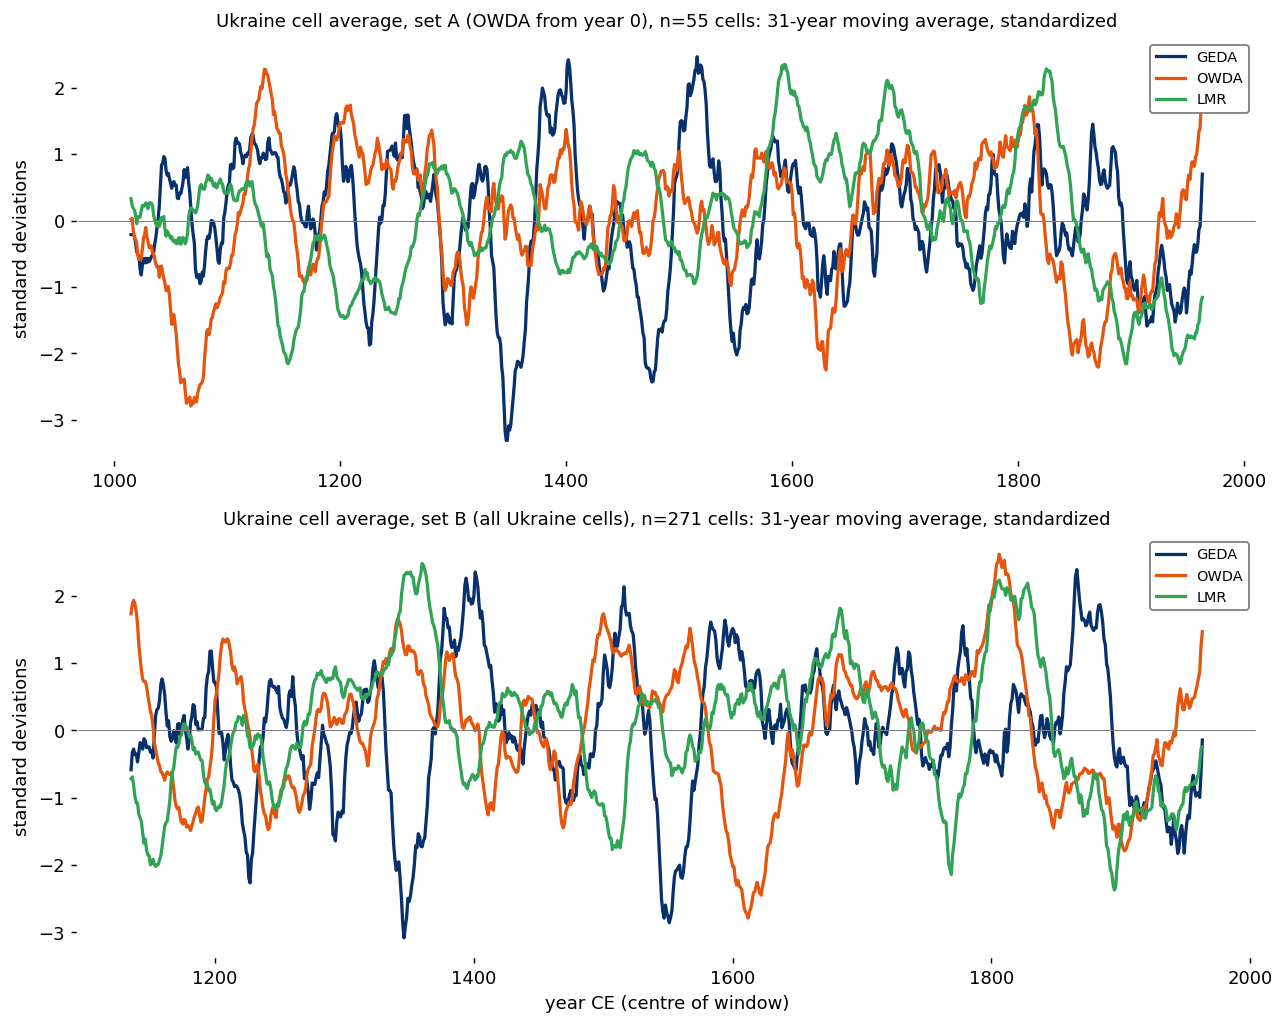

In [25]:
# Cell 17
# The 31-year smoothed, standardized cell-average series for the two Ukraine cell sets (needs Cell 16).
import matplotlib.pyplot as plt
from IPython.display import Image as IPImage, display

OUT = ROOT / 'output' / 'edop' / 'regionality'
OUT.mkdir(parents=True, exist_ok=True)
outpath = OUT / 'wo01_ukraine_lowfreq.png'
COL = {'GEDA': '#08306b', 'OWDA': '#e6550d', 'LMR': '#31a354'}
w = 31

print('drawing figure...')
fig, axes = plt.subplots(2, 1, figsize=(10, 8))
fig.patch.set_facecolor('white')
for ax, (name, d) in zip(axes, lf.items()):
    ax.set_facecolor('white')
    centres = d['years'][w // 2: len(d['years']) - w // 2]
    for k in ('GEDA', 'OWDA', 'LMR'):
        s = smooth(d[k], w)
        ax.plot(centres, z(s), color=COL[k], lw=1.8, label=k)
    ax.axhline(0, color='grey', lw=0.6)
    ax.set_title(f'Ukraine cell average, set {name}, n={d["n"]} cells: {w}-year moving average, standardized', color='black', fontsize=10)
    ax.set_ylabel('standard deviations', color='black')
    ax.tick_params(colors='black')
    leg = ax.legend(loc='upper right', fontsize=8, framealpha=1, facecolor='white', edgecolor='grey')
    for t in leg.get_texts():
        t.set_color('black')
axes[1].set_xlabel('year CE (centre of window)', color='black')
fig.tight_layout()
fig.savefig(outpath, facecolor='white', dpi=130, bbox_inches='tight')
plt.close(fig)
display(IPImage(str(outpath)))
